# Hangman greedy-strategy explorer

Look at the greedy strategy's results from `strategy.py`. Pick a word length,
then explore: the best opening letters, which words are hardest, how average
misses scale with length, and how tweaking per-word frequencies moves the number.

Reminders: a *miss* is a wrong letter guess; frequencies are non-normalized and
default to 1 per word; the greedy rule guesses the un-guessed letter with the
highest combined frequency of candidate words that contain it.

In [ ]:
from pathlib import Path
import sys

def find_math_dir():
    cwd = Path.cwd().resolve()
    for c in (cwd, cwd.parent, cwd.parent.parent, cwd / 'math', cwd.parent / 'math'):
        if (c / 'strategy.py').exists():
            return c
    raise FileNotFoundError('Could not find strategy.py. Open from the repo root, math/, or math/notebooks/.')

math_dir = find_math_dir()
if str(math_dir) not in sys.path:
    sys.path.insert(0, str(math_dir))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import strategy
import wordlist

print(f'imported strategy from {math_dir}')

## Pick a length and a distribution

Change `LENGTH` and `WEIGHTING`, then re-run the rest. `WEIGHTING` selects the
word-choice distribution — how likely each word is to be the secret word:

- `"uniform"` — every word equally likely (the default).
- `"zipf"` — real English frequency (common words weigh more).
- `"greedy"` / `"best_opener"` — the adversarial word-setter from
  `freq_search.py`, tuned to make each guesser work hardest (needs a
  `freq_search` run for this length).

`wordlist.resolve_weighting` turns the name into a `freq` vector (or `None` for
uniform) that every cell below threads into the solver. `GreedyGame` is built
once; only the solve re-runs.

In [ ]:
LENGTH    = 5          # <-- choose a word length
WEIGHTING = "uniform"  # <-- "uniform", "zipf", "greedy", or "best_opener"

g = strategy.GreedyGame(LENGTH)
freq = wordlist.resolve_weighting(WEIGHTING, LENGTH)   # None (uniform) / dict / array
# `freq` is threaded through every cell below. Switch WEIGHTING and re-run.

print(f'{g.N:,} words of length {LENGTH}  (zipf >= 2.5)   weighting: {WEIGHTING}')
print(f'greedy opens with: {g.greedy_first_letter(freq)!r}')
print(f'Mode A  average misses: {g.average_misses(freq):.4f}')

## Best opening letters (Mode B)

Expected misses if each letter is forced as the first guess, then greedy is
played. The dashed line is the greedy opener (the best one).

In [ ]:
by_letter = g.misses_by_starting_letter(freq)      # sorted best-first
mb = pd.Series(by_letter, name='avg_misses')
mb.index.name = 'first_letter'

fig, ax = plt.subplots(figsize=(10, 3.5))
ax.bar(mb.index, mb.values, color='#3b6ea5')
ax.axhline(g.average_misses(freq), color='#cc4444', ls='--', lw=1, label='greedy opener')
ax.set_ylabel('avg misses')
ax.set_title(f'Expected misses by opening letter (length {LENGTH}, {WEIGHTING})')
ax.legend()
plt.show()

mb.to_frame().T

## Per-word difficulty

How many misses the greedy strategy makes on each word, and the distribution.

In [ ]:
pwm = g.per_word_misses(freq)
words = pd.DataFrame({'word': g.words, 'misses': pwm.astype(int)})

print(f'solved with 0 misses: {(pwm == 0).sum():,} words')
print(f'max misses: {int(pwm.max())}   mean: {pwm.mean():.3f}')

fig, ax = plt.subplots(figsize=(9, 3))
ax.hist(pwm, bins=range(0, int(pwm.max()) + 2), color='#3b6ea5', align='left', rwidth=0.85)
ax.set_xlabel('misses'); ax.set_ylabel('# words')
ax.set_title(f'Misses per word (length {LENGTH})')
plt.show()

print('hardest words:')
words.sort_values('misses', ascending=False).head(12).reset_index(drop=True)

## Trace one word

The actual greedy guess sequence for a word: each guess and whether it hit.

In [ ]:
WORD = g.words[int(pwm.argmax())]      # the hardest word; or set your own, e.g. 'bench'

hits = g.trace(WORD, freq)
n_miss = sum(1 for _, hit in hits if not hit)
print(f'{WORD!r}: {n_miss} misses')
for letter, hit in hits:
    mark = 'hit ' if hit else 'MISS'
    print(f'  {letter}  {mark}')

## Inspect a tree node

Give a board (revealed letters + `_` blanks, e.g. `"b_ll_"`) and the letters
that were missed, and `show_state` finds that node in the greedy tree for the
current `freq`: how many candidate words remain, greedy's next guess, and every
outcome that guess can produce. States greedy would never actually reach are
flagged with the reason. Remember a hit reveals **all** positions of a letter,
so put every occurrence of a revealed letter on the board.

In [ ]:
_UNSET = object()

def show_state(board, missed="", f=_UNSET):
    """Locate `board` (+ missed letters) in the greedy tree and print greedy's
    next guess and every outcome it can lead to. `board` is a length-LENGTH
    string of revealed letters and `_` blanks, e.g. 'b_ll_'; `missed` is a
    string or list of absent letters. Defaults to the current `freq`."""
    st = g.state(board, missed, freq if f is _UNSET else f)
    tag = 'reachable' if st['reachable'] else 'NOT REACHED by greedy'
    print(f"board {st['board']!r}   missed [{','.join(st['missed'])}]   ({tag})")
    if not st['reachable']:
        print(f"  {st['reason']}")
        return st
    if st['determined']:
        word = st['candidates'][0] if st['candidates'] else '(none)'
        print(f"  word determined: {word}")
        return st
    print(f"  {st['n']} candidates, e.g. {', '.join(st['candidates'][:8])}")
    print(f"  greedy guesses: {st['guess']!r}")
    for o in st['outcomes']:
        kind = 'HIT ' if o['hit'] else 'miss'
        print(f"    {kind} -> {o['board']!r}  ({o['n']:>4} words)  e.g. {', '.join(o['sample'][:5])}")
    return st

# example: the two outcomes of greedy's opener (empty board, nothing missed)
_ = show_state('_' * LENGTH)

## All situations at depth k

Every node greedy can reach after exactly `k` guesses, with the choice it makes
there. Depth 0 is the opener; at depth `k`, `k` guesses are in and `guess` is
the next one. Branches already solved by depth `k` show `guess = None` (and
`determined = True`); branches that finished earlier aren't at depth `k` at all.

In [ ]:
DEPTH = 2      # <-- number of guesses already made

rows = g.states_at_depth(DEPTH, freq)
sit = pd.DataFrame(rows)
sit['missed'] = sit['missed'].apply(''.join)
sit['sample'] = sit['sample'].apply(lambda s: ' '.join(s[:4]))

live = sit[~sit['determined']]
print(f'depth {DEPTH}: {len(sit)} nodes  ({len(live)} still undetermined)')
if len(live):
    spread = ', '.join(f'{k}={v}' for k, v in live['guess'].value_counts().items())
    print(f'next greedy guess spread: {spread}')

# biggest (most ambiguous) situations first
sit.sort_values('n', ascending=False).head(20).reset_index(drop=True)

## Average misses by length

How the greedy average scales across word lengths (builds a `GreedyGame` per
length; Mode A is fast).

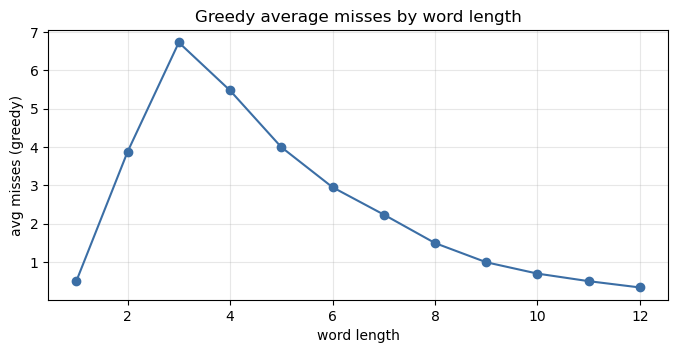

,length,avg_misses
0,1,0.500
1,2,3.878
2,3,6.731
3,4,5.478
4,5,3.999
5,6,2.952
6,7,2.238
7,8,1.494
8,9,0.993
9,10,0.697


In [6]:
lengths = list(range(1, 13))
avgs = [strategy.GreedyGame(L).average_misses() for L in lengths]

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(lengths, avgs, 'o-', color='#3b6ea5')
ax.set_xlabel('word length'); ax.set_ylabel('avg misses (greedy)')
ax.set_title('Greedy average misses by word length')
ax.grid(alpha=0.3)
plt.show()

pd.DataFrame({'length': lengths, 'avg_misses': [round(a, 3) for a in avgs]})

## Tweaking frequencies

Frequencies default to 1 for every word. Build the `GreedyGame` once, then pass
a `freq` vector to re-solve (~25 ms each). `freq` can be a numpy array aligned to
`g.words`, a `{word: frequency}` dict, or a `callable(word) -> float`.

In [7]:
w0 = g.words[0]        # the most frequent word of this length (list is freq-sorted)

f = g.ones()
f[0] = 100.0           # make w0 dominate the weighting
print(f'boosting {w0!r} 100x:')
print(f'  baseline avg : {g.average_misses():.4f}')
print(f'  tweaked  avg : {g.average_misses(f):.4f}')

# dict form (missing words default to 1):
# g.average_misses({w0: 100.0})

boosting 'about' 100x:
  baseline avg : 3.9989
  tweaked  avg : 3.9432
